# 01 · Análisis exploratorio — Producción no convencional
**Objetivo del proyecto:** predecir la producción mensual de **petróleo** y **gas** de pozos no convencionales de la **Cuenca Neuquina**.

Fuente: Secretaría de Energía de la Nación, *Producción de pozos de gas y petróleo no convencional* (Capítulo IV). Una fila = un pozo en un mes.
Unidades: petróleo en **m³**, gas en **miles de m³ (Mm³)**, `tef` = días efectivos de producción en el mes.

Usamos **Polars** (lectura lazy, mucho más rápida que pandas sobre 139 MB) y **DuckDB** para consultas SQL directas.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, polars as pl, duckdb
import matplotlib.pyplot as plt, seaborn as sns
from ypf_ds import config
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.figsize"] = (11, 4.5)
config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

In [2]:
from ypf_ds.data.load import escanear_crudo, diagnostico
crudo = pl.read_csv(config.DATA_RAW, encoding="utf8-lossy", infer_schema_length=None)
print(crudo.shape)
crudo.head(3)

(421046, 40)


idempresa,anio,mes,idpozo,prod_pet,prod_gas,prod_agua,iny_agua,iny_gas,iny_co2,iny_otro,tef,vida_util,tipoextraccion,tipoestado,tipopozo,observaciones,fechaingreso,rectificado,habilitado,idusuario,empresa,sigla,formprod,profundidad,formacion,idareapermisoconcesion,areapermisoconcesion,idareayacimiento,areayacimiento,cuenca,provincia,coordenadax,coordenaday,tipo_de_recurso,proyecto,clasificacion,subclasificacion,sub_tipo_recurso,fecha_data
str,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,str,i64,str,str,str,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str
"""YSUR""",2015,1,132909,16.74,241.22,13.42,0.0,0.0,0.0,0.0,31.0,null,"""Plunger Lift""","""Extracción Efectiva""","""Gasífero""",null,"""2015-02-26 13:35:35.533458""","""f""","""t""",5,"""YSUR ENERGÍA ARGENTINA S.R.L.""","""AEA.NQ.RCo-1039""","""PREC""",2678.0,"""precuyo""","""SDD""","""AL SUR DE LA DORSAL""","""RQC""","""RANQUIL CO""","""NEUQUINA""","""Neuquén""",-69.202207,-39.08182,"""NO CONVENCIONAL""","""GAS PLUS""","""EXPLOTACION""","""DESARROLLO""","""TIGHT""","""2015-01-31"""
"""YSUR""",2018,1,132488,0.0,171.937,0.0,0.0,0.0,0.0,0.0,30.73,null,"""Surgencia Natural""","""Extracción Efectiva""","""Gasífero""",null,"""2018-02-10 08:37:14.717426""","""f""","""t""",444,"""YSUR ENERGÍA ARGENTINA S.R.L.""","""AEA.RN.EFO-99(d)""","""LAJA""",3828.0,"""lajas""","""FEO""","""ESTACION FERNANDEZ ORO""","""Z155""","""ESTACION FERNANDEZ ORO""","""NEUQUINA""","""Rio Negro""",-67.86496,-39.016722,"""NO CONVENCIONAL""","""GAS PLUS""","""EXPLOTACION""","""DESARROLLO""","""TIGHT""","""2018-01-31"""
"""YSUR""",2017,1,134325,22.34,365.61,1.2,0.0,0.0,0.0,0.0,31.0,null,"""Plunger Lift""","""Extracción Efectiva""","""Gasífero""",null,"""2017-02-16 13:45:37.233373""","""f""","""t""",444,"""YSUR ENERGÍA ARGENTINA S.R.L.""","""APA.RN.EFO-117(d)""","""LAJA""",3793.0,"""lajas""","""FEO""","""ESTACION FERNANDEZ ORO""","""Z155""","""ESTACION FERNANDEZ ORO""","""NEUQUINA""","""Rio Negro""",-67.849735,-39.020644,"""NO CONVENCIONAL""","""GAS PLUS""","""EXPLOTACION""","""DESARROLLO""","""TIGHT""","""2017-01-31"""


## 1. Estructura y calidad del dato crudo

In [3]:
nulos = (crudo.null_count() / crudo.height * 100).transpose(include_header=True, column_names=["pct_nulos"])
nulos.filter(pl.col("pct_nulos") > 0).sort("pct_nulos", descending=True)

column,pct_nulos
str,f64
"""vida_util""",97.871016
"""observaciones""",93.734651
"""clasificacion""",0.218978
"""subclasificacion""",0.218978
"""tipoextraccion""",0.145827
"""tipoestado""",0.145827
"""tipopozo""",0.145827
"""sub_tipo_recurso""",0.107352


`vida_util` y `observaciones` están prácticamente vacías. Las columnas `iny_*` (inyección) son casi siempre 0 porque el dataset es de pozos productores.

In [4]:
duckdb.sql("""
SELECT cuenca, COUNT(*) filas, COUNT(DISTINCT idpozo) pozos,
       ROUND(SUM(prod_pet)/1e6, 2) pet_Mm3, ROUND(SUM(prod_gas)/1e6, 2) gas_MMm3
FROM crudo GROUP BY cuenca ORDER BY filas DESC""").df()

,cuenca,filas,pozos,pet_Mm3,gas_MMm3
0,NEUQUINA,404037,4862,140.05,255.19
1,AUSTRAL,16197,209,0.31,9.58
2,GOLFO SAN JORGE,627,15,0.12,0.35
3,NOROESTE,185,3,0.02,0.00


La **Cuenca Neuquina** concentra el 96% de las filas y la casi totalidad del petróleo. Las otras cuencas tienen muy pocos pozos (y geología distinta), así que **filtramos solo Neuquina**: un modelo especializado en una cuenca es más preciso que uno que mezcla reservorios diferentes.

In [5]:
diag = diagnostico(escanear_crudo().filter(pl.col("cuenca") == "NEUQUINA"))
diag

{'filas': 404037,
 'pozos': 4862,
 'duplicados_pozo_mes': 0,
 'nulos_pct': {'tipoextraccion': 0.15,
  'tipoestado': 0.15,
  'tipopozo': 0.15,
  'sub_tipo_recurso': 0.03},
 'negativos': {'prod_pet': 0, 'prod_gas': 2, 'prod_agua': 0, 'tef': 0},
 'profundidad_fuera_rango': 6788,
 'coordenadas_invertidas': 68}

## 2. Hallazgos de calidad en Neuquina

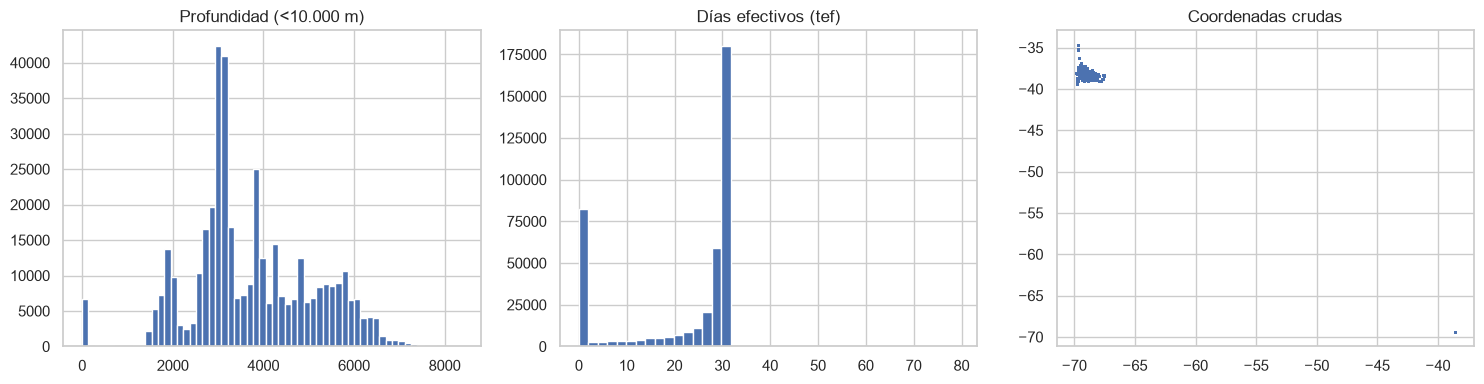

Profundidad máx: 378939.0 | ceros: 5738 | tef > 31: 15


In [6]:
neu = crudo.filter(pl.col("cuenca") == "NEUQUINA")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
prof = neu["profundidad"].to_numpy()
ax[0].hist(prof[prof < 10000], bins=60); ax[0].set_title("Profundidad (<10.000 m)")
ax[1].hist(neu["tef"].to_numpy(), bins=40); ax[1].set_title("Días efectivos (tef)")
ax[2].scatter(neu["coordenadax"], neu["coordenaday"], s=1, alpha=.3); ax[2].set_title("Coordenadas crudas")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_calidad.png", dpi=110); plt.show()
print("Profundidad máx:", prof.max(), "| ceros:", (prof == 0).sum(), "| tef > 31:", (neu["tef"] > 31).sum())

- **Profundidad:** un pozo con 378.939 m (error de carga) y ~1,4% de filas en 0 → se tratan como faltantes.
- **tef:** algunos meses superan los días del mes; y hay meses con producción pero `tef = 0`.
- **Coordenadas:** un pozo tiene latitud y longitud invertidas (el punto aislado del scatter).

## 3. Distribución de la producción

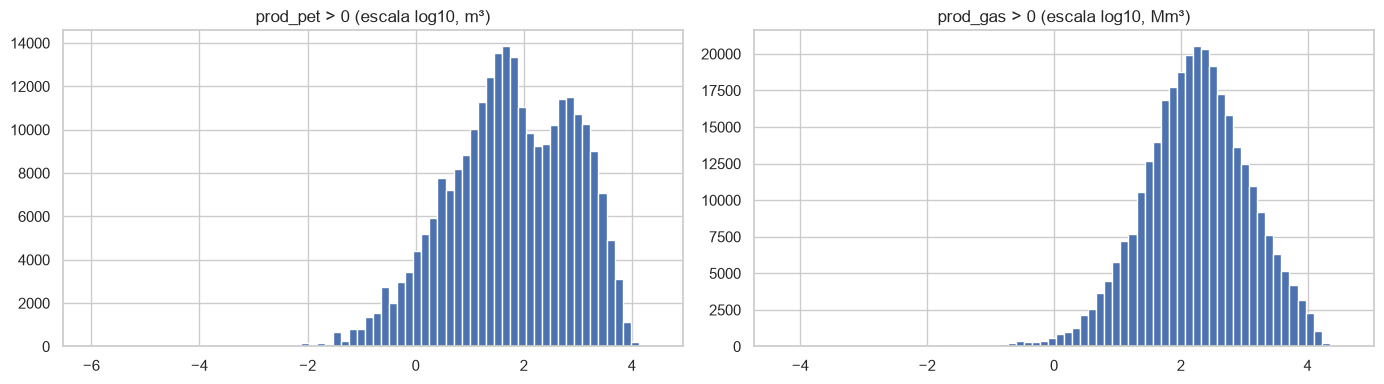

prod_pet_q50,prod_gas_q50,prod_pet_q90,prod_gas_q90,prod_pet_q99,prod_gas_q99
f64,f64,f64,f64,f64,f64
7.20497,95.65,1046.977,1561.181,4958.28,8922.283


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, c, u in [(ax[0], "prod_pet", "m³"), (ax[1], "prod_gas", "Mm³")]:
    v = neu[c].to_numpy(); v = v[v > 0]
    a.hist(np.log10(v), bins=70); a.set_title(f"{c} > 0 (escala log10, {u})")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_distribucion.png", dpi=110); plt.show()
neu.select(pl.col("prod_pet", "prod_gas").quantile(q).name.suffix(f"_q{int(q*100)}") for q in [.5, .9, .99])

Distribuciones **fuertemente sesgadas a la derecha** (el percentil 99 es cientos de veces la mediana) → modelamos en escala `log1p`.

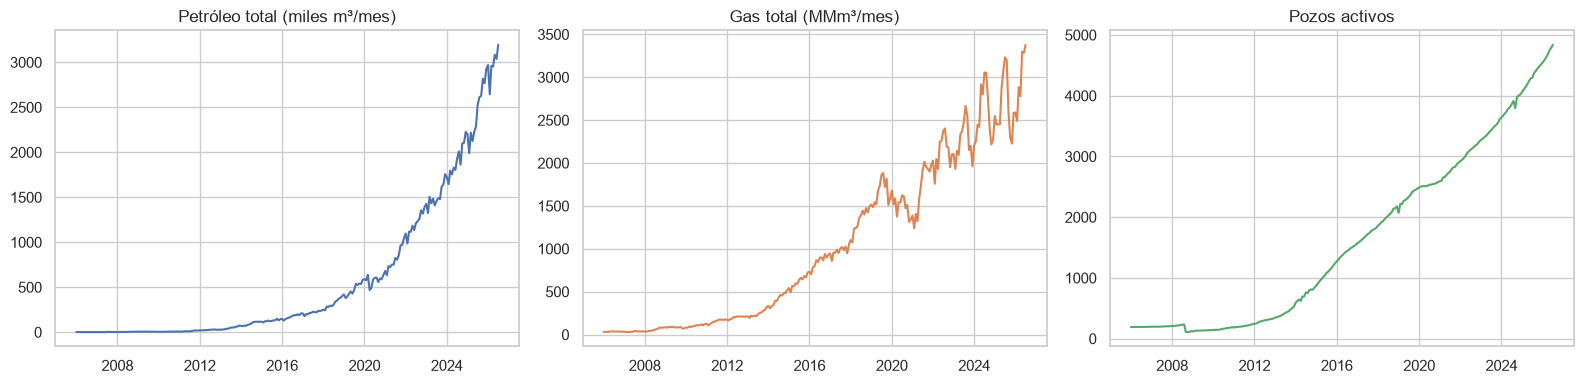

In [8]:
serie = duckdb.sql("""
SELECT make_date(anio, mes, 1) fecha, SUM(prod_pet) pet, SUM(prod_gas) gas, COUNT(DISTINCT idpozo) pozos
FROM neu GROUP BY 1 ORDER BY 1""").df()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(serie.fecha, serie.pet / 1e3); ax[0].set_title("Petróleo total (miles m³/mes)")
ax[1].plot(serie.fecha, serie.gas / 1e3, color="C1"); ax[1].set_title("Gas total (MMm³/mes)")
ax[2].plot(serie.fecha, serie.pozos, color="C2"); ax[2].set_title("Pozos activos")
plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / "01_serie_temporal.png", dpi=110); plt.show()

El boom de Vaca Muerta es evidente desde 2014 en petróleo. El gas tight (Lajas, Mulichinco, Punta Rosada) explica buena parte del gas temprano.

In [9]:
formaciones = duckdb.sql("""
SELECT formacion, COUNT(DISTINCT idpozo) pozos, ROUND(SUM(prod_pet)/1e3) pet_miles_m3, ROUND(SUM(prod_gas)/1e3) gas_MMm3
FROM neu GROUP BY 1 ORDER BY pet_miles_m3 DESC LIMIT 10""").df()
formaciones

,formacion,pozos,pet_miles_m3,gas_MMm3
0,vaca muerta,3382,135488.0,159010.0
1,lajas,589,2578.0,37357.0
2,punta rosada,112,908.0,13477.0
3,mulichinco,259,414.0,24221.0
4,quintuco,86,186.0,994.0
5,los molles,216,174.0,5457.0
6,precuyo,81,150.0,4635.0
7,agrio,78,87.0,8787.0
8,lotena,10,21.0,533.0
9,basamento,16,19.0,426.0


## 4. Petróleo vs gas por pozo: la relación gas/petróleo (GOR)

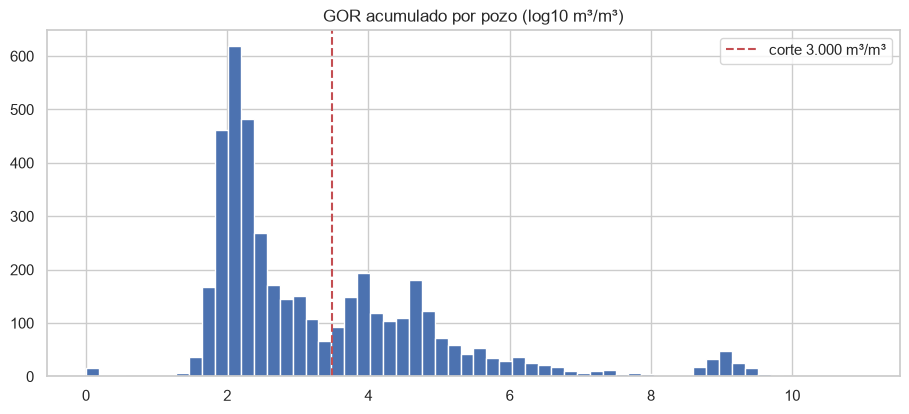

In [10]:
por_pozo = duckdb.sql("""
SELECT idpozo, SUM(prod_pet) pet, SUM(prod_gas) gas, ANY_VALUE(tipopozo) tipopozo
FROM neu GROUP BY 1 HAVING SUM(prod_pet) > 0""").df()
por_pozo["gor"] = por_pozo.gas * 1000 / por_pozo.pet
plt.hist(np.log10(por_pozo.gor.clip(1, None)), bins=60); plt.axvline(np.log10(3000), color="r", ls="--", label="corte 3.000 m³/m³")
plt.title("GOR acumulado por pozo (log10 m³/m³)"); plt.legend()
plt.savefig(config.DIR_FIGURAS / "01_gor.png", dpi=110); plt.show()

El GOR es **bimodal**: hay un grupo de pozos de petróleo (GOR de cientos) y otro de gas (GOR de decenas de miles). Esto justifica **modelar petróleo y gas por separado** y usar un corte de 3.000 m³/m³ para clasificar el fluido del pozo.

## 5. Historia de los pozos

In [11]:
meses = duckdb.sql("SELECT idpozo, COUNT(*) n, MIN(anio*12+mes) ini, MAX(anio*12+mes) fin FROM neu GROUP BY 1").df()
meses["huecos"] = (meses.fin - meses.ini + 1) - meses.n
print(f"Pozos con meses faltantes: {(meses.huecos > 0).sum()} de {len(meses)}")
meses.n.describe()

Pozos con meses faltantes: 703 de 4862


count    4862.000000
mean       83.100987
std        58.869762
min         1.000000
25%        31.000000
50%        82.000000
75%       128.000000
max       247.000000
Name: n, dtype: float64

Hay pozos con **meses sin fila** (paradas). Por eso la limpieza arma una **grilla mensual continua por pozo**: así los "lags" (mes anterior, hace 3 meses…) son realmente meses calendario y no filas.

**Conclusiones del EDA → decisiones de limpieza (notebook 02):**
1. Filtrar Neuquina y pozos productores. 2. Profundidad imposible → imputar por formación/yacimiento. 3. `tef` acotado a días del mes. 4. Corregir coordenadas invertidas. 5. Grilla mensual continua. 6. Escala log para producción. 7. Separar petróleo y gas.